# Erro da regra do ponto médio



A regra do ponto médio aproxima a integral de uma função `f(x)` no intervalo `[a,b]` por

$$ M = (b-a) f\left(\frac{a+b}{2}\right). $$

A integral exata e

$$ I = \int_a^b f(x)\,dx. $$

O erro assinado será definido como

$$ E = I - M. $$

Para uma funcao com segunda derivada contínua, a fórmula teórica do erro da regra do ponto médio simples e

$$ E = \frac{f''(\xi)}{24}(b-a)^3, \qquad \xi \in (a,b). $$

Como normalmente nao sabemos o ponto `xi`, usamos tambem o limite superior do erro absoluto:

$$ |E| \leq \frac{(b-a)^3}{24}\max_{x\in[a,b]} |f''(x)|. $$

Se o erro for definido como `M - I`, o sinal da fórmula muda:

$$ M - I = -\frac{f''(\xi)}{24}(b-a)^3. $$

## Como usar

1. Escolhe-se a função na variável `função`.
2. Escolhe-se os intervalos em `intervalos`.
3. Executa-se as células.

Exemplos de funções válidas: `sin(x)`, `exp(x)`, `x**3 + 2*x`, `log(x)`, `sqrt(x)`. Para `log(x)` e `sqrt(x)`, escolhe-se intervalos onde a funcao esteja definida.

In [17]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize_scalar

x = sp.symbols('x')

# Altere aqui a funcao e os intervalos.
funcao = "sin(x)+x**2"
intervalos = [(0, 1), (1, 2), (2, 3)]

f_expr = sp.sympify(funcao)
f2_expr = sp.diff(f_expr, x, 2)
f = sp.lambdify(x, f_expr, modules=["numpy"])
f2 = sp.lambdify(x, f2_expr, modules=["numpy"])

print("\nf(x)  =", sp.pretty(f_expr))
print("f''(x) =", sp.pretty(f2_expr))


f(x)  =  2         
x  + sin(x)
f''(x) = 2 - sin(x)


## Funções auxiliares

Para cada intervalo `[a,b]`, o codigo calcula:

- `I`: integral exata numerica de `f(x)`;
- `M`: aproximação pela regra do ponto médio;
- `E = I - M`: erro assinado;
- `|E|`: erro absoluto;
- `limite teorico`: valor de $\frac{(b-a)^3}{24}\max |f''(x)|$.

O maximo de `|f''(x)|` e estimado por uma busca numerica. Por isso, o limite teorico impresso deve ser lido como uma estimativa numerica do limite.

In [2]:
def integral_exata(a, b):
    valor, _ = quad(lambda t: float(f(t)), a, b)
    return valor

def ponto_medio(a, b):
    m = (a + b) / 2
    return (b - a) * float(f(m))

def max_abs_f2(a, b):
    """Estima max |f''(x)| em [a,b] combinando amostragem e otimizacao."""
    grade = np.linspace(a, b, 1001)
    valores = np.abs(f2(grade))
    valores = np.where(np.isfinite(valores), valores, np.nan)
    candidatos = []

    if np.any(np.isfinite(valores)):
        candidatos.append(float(np.nanmax(valores)))

    try:
        res = minimize_scalar(lambda t: -abs(float(f2(t))), bounds=(a, b), method="bounded")
        if res.success:
            candidatos.append(abs(float(f2(res.x))))
    except Exception:
        pass

    return max(candidatos) if candidatos else np.nan

def erro_ponto_medio(a, b):
    I = integral_exata(a, b)
    M = ponto_medio(a, b)
    E = I - M
    maximo = max_abs_f2(a, b)
    limite = ((b - a) ** 3 / 24) * maximo
    return {
        "intervalo": f"[{a}, {b}]",
        "a": a,
        "b": b,
        "ponto_medio": (a + b) / 2,
        "integral_exata_I": I,
        "aproximacao_M": M,
        "erro_E_I_menos_M": E,
        "erro_absoluto": abs(E),
        "max_abs_f2_estimado": maximo,
        "limite_teorico_estimado": limite,
    }

## Resultado nos intervalos escolhidos

A coluna mais importante para especificar o erro real e `erro_E_I_menos_M`. Ela mostra quanto falta para a aproximacao pelo ponto medio chegar a integral exata, usando a convencao

$$E = I - M.$$

Se `E > 0`, a regra do ponto medio fica abaixo da integral exata. Se `E < 0`, fica acima.

In [3]:
resultados = [erro_ponto_medio(a, b) for a, b in intervalos]

for r in resultados:
    print(f"Intervalo {r['intervalo']}")
    print(f"  ponto medio                 = {r['ponto_medio']:.10f}")
    print(f"  integral exata I            = {r['integral_exata_I']:.10f}")
    print(f"  aproximacao M               = {r['aproximacao_M']:.10f}")
    print(f"  erro assinado E = I - M     = {r['erro_E_I_menos_M']:.10e}")
    print(f"  erro absoluto |E|           = {r['erro_absoluto']:.10e}")
    print(f"  max |f''(x)| estimado       = {r['max_abs_f2_estimado']:.10f}")
    print(f"  limite teorico estimado     = {r['limite_teorico_estimado']:.10e}")
    print()

Intervalo [0, 1]
  ponto medio                 = 0.5000000000
  integral exata I            = 0.7930310275
  aproximacao M               = 0.7294255386
  erro assinado E = I - M     = 6.3605488861e-02
  erro absoluto |E|           = 6.3605488861e-02
  max |f''(x)| estimado       = 2.0000000000
  limite teorico estimado     = 8.3333333333e-02

Intervalo [1, 2]
  ponto medio                 = 1.5000000000
  integral exata I            = 3.2897824757
  aproximacao M               = 3.2474949866
  erro assinado E = I - M     = 4.2287489145e-02
  erro absoluto |E|           = 4.2287489145e-02
  max |f''(x)| estimado       = 1.1585290152
  limite teorico estimado     = 4.8272042300e-02

Intervalo [2, 3]
  ponto medio                 = 2.5000000000
  integral exata I            = 6.9071789934
  aproximacao M               = 6.8484721441
  erro assinado E = I - M     = 5.8706849283e-02
  erro absoluto |E|           = 5.8706849283e-02
  max |f''(x)| estimado       = 1.8588799919
  limite teoric

## Visualização

Em cada intervalo, o retangulo usa altura `f(m)`, onde `m` e o ponto médio. A área do retangulo representa `M = (b-a)f(m)`. A diferença entre essa área e a área real sob a curva e o erro.

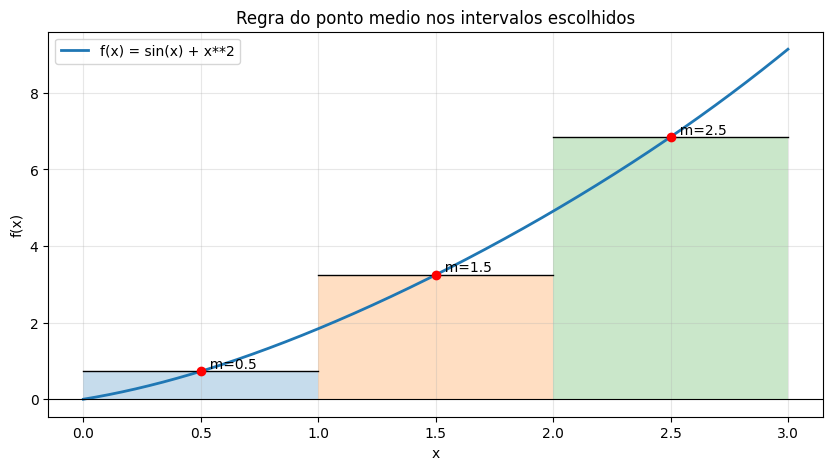

In [4]:
a_total = min(a for a, b in intervalos)
b_total = max(b for a, b in intervalos)
xx = np.linspace(a_total, b_total, 1000)

plt.figure(figsize=(10, 5))
plt.plot(xx, f(xx), label=f"f(x) = {funcao}", linewidth=2)

for a, b in intervalos:
    m = (a + b) / 2
    altura = float(f(m))
    plt.fill_between([a, b], [altura, altura], alpha=0.25, step="post")
    plt.plot([a, b], [altura, altura], color="black", linewidth=1)
    plt.scatter([m], [altura], color="red", zorder=3)
    plt.text(m, altura, f"  m={m:g}", va="bottom")

plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Regra do ponto medio nos intervalos escolhidos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Regra do Ponto Médio Composta

Divida $$[a,b]$$em$$n$$subintervalos:

$$
x_i=a+ih,\qquad i=0,1,\dots,n
$$ com

$$
h=\frac{b-a}{n}.
$$

O ponto médio de $$[x_i,x_{i+1}]$$ é

$$
\bar{x}_i=\frac{x_i+x_{i+1}}{2}.
$$

Substituindo:

$$
\bar{x}_i
=
\frac{a+ih+a+(i+1)h}{2}
$$

$$
\bar{x}_i
=
a+\left(i+\frac12\right)h.
$$

Logo,

$$
\int_{x_i}^{x_{i+1}} f(x)\,dx
\approx
h f(\bar{x}_i).
$$

Somando:

$$
\int_a^b f(x)\,dx
=
\sum_{i=0}^{n-1}
\int_{x_i}^{x_{i+1}} f(x)\,dx
$$

$$
\int_a^b f(x)\,dx
\approx
h\sum_{i=0}^{n-1}f(\bar{x}_i).
$$

Portanto,

$$
\boxed{
M_n=
h\sum_{i=0}^{n-1}
f\left(a+\left(i+\frac12\right)h\right)
}
$$

# Erro

Considere o subintervalo $$[x_i,x_{i+1}]$$, com ponto médio $$\bar{x}_i$$.

Faça

$$
x=\bar{x}_i+t.
$$

Então,

$$
t\in\left[-\frac h2,\frac h2\right].
$$

Pelo Teorema de Taylor:

$$
f(\bar{x}_i+t)
=
f(\bar{x}_i)
+
f'(\bar{x}_i)t
+
\frac{f''(\xi_i)}{2}t^2,
\qquad
\xi_i\in(x_i,x_{i+1}).
$$

Integrando:

$$
\int_{x_i}^{x_{i+1}} f(x)\,dx
=
\int_{-h/2}^{h/2}
f(\bar{x}_i+t)\,dt
$$

$$
=
\int_{-h/2}^{h/2}
\left[
f(\bar{x}_i)
+
f'(\bar{x}_i)t
+
\frac{f''(\xi_i)}{2}t^2
\right]dt.
$$

Separando:

$$
=
f(\bar{x}_i)
\int_{-h/2}^{h/2}dt
+
f'(\bar{x}_i)
\int_{-h/2}^{h/2}t\,dt
+
\frac{f''(\xi_i)}{2}
\int_{-h/2}^{h/2}t^2\,dt.
$$

Calculando:

$$
\int_{-h/2}^{h/2}dt=h
$$

$$
\int_{-h/2}^{h/2}t\,dt=0
$$

$$
\int_{-h/2}^{h/2}t^2\,dt
=
\left[\frac{t^3}{3}\right]_{-h/2}^{h/2}
=
\frac{h^3}{12}.
$$

Logo,

$$
\int_{x_i}^{x_{i+1}} f(x)\,dx
=
h f(\bar{x}_i)
+
\frac{f''(\xi_i)}{2}
\frac{h^3}{12}
$$

$$
\int_{x_i}^{x_{i+1}} f(x)\,dx
=
h f(\bar{x}_i)
+
\frac{h^3}{24}f''(\xi_i).
$$

Então,

$$
E_i=
\int_{x_i}^{x_{i+1}} f(x)\,dx
-
h f(\bar{x}_i)
$$

$$
\boxed{
E_i=
\frac{h^3}{24}f''(\xi_i)
}
$$

# Erro Composto

$$
E_n=I-M_n
$$

$$
E_n=
\sum_{i=0}^{n-1}
\left[
\int_{x_i}^{x_{i+1}} f(x)\,dx
-
h f(\bar{x}_i)
\right]
$$

$$
E_n=
\sum_{i=0}^{n-1}
\frac{h^3}{24}f''(\xi_i)
$$

$$
E_n=
\frac{h^3}{24}
\sum_{i=0}^{n-1}f''(\xi_i).
$$

Pelo valor médio para somas:

$$
\sum_{i=0}^{n-1}f''(\xi_i)
=
n f''(\xi),
\qquad \xi\in(a,b).
$$

Assim,

$$
E_n=
\frac{h^3}{24}
n f''(\xi).
$$

Como

$$
nh=b-a,
$$

temos

$$
E_n=
\frac{h^2}{24}
(b-a)f''(\xi).
$$

Portanto,

$$
\boxed{
E_n
=
I-M_n
=
\frac{(b-a)h^2}{24}f''(\xi),
\qquad \xi\in(a,b)
}
$$

# Limite Superior

$$
|E_n|
=
\left|
\frac{(b-a)h^2}{24}f''(\xi)
\right|
$$

$$
|E_n|
=
\frac{(b-a)h^2}{24}
|f''(\xi)|
$$

Como

$$
|f''(\xi)|
\leq
\max_{x\in[a,b]}|f''(x)|,
$$

segue que

$$
\boxed{
|E_n|
\leq
\frac{(b-a)h^2}{24}
\max_{x\in[a,b]}|f''(x)|
}
$$

In [5]:
def ponto_medio_composto(a, b, n):
    h = (b - a) / n
    pontos_medios = a + (np.arange(n) + 0.5) * h
    return h * np.sum(f(pontos_medios))

# Exemplo composto no intervalo total.
a, b = a_total, b_total
for n in [1, 2, 4, 8, 16, 32]:
    I = integral_exata(a, b)
    Mn = ponto_medio_composto(a, b, n)
    h = (b - a) / n
    E = I - Mn
    limite = ((b - a) * h**2 / 24) * max_abs_f2(a, b)
    print(f"n={n:2d} | M_n={Mn:.10f} | E=I-M_n={E:.10e} | |E|={abs(E):.10e} | limite estimado={limite:.10e}")

n= 1 | M_n=9.7424849598 | E=I-M_n=1.2475075368e+00 | |E|=1.2475075368e+00 | limite estimado=2.2500000000e+00
n= 2 | M_n=10.6270679354 | E=I-M_n=3.6292456123e-01 | |E|=3.6292456123e-01 | limite estimado=5.6250000000e-01
n= 4 | M_n=10.8967846526 | E=I-M_n=9.3207844047e-02 | |E|=9.3207844047e-02 | limite estimado=1.4062500000e-01
n= 8 | M_n=10.9665443615 | E=I-M_n=2.3448135112e-02 | |E|=2.3448135112e-02 | limite estimado=3.5156250000e-02
n=16 | M_n=10.9841214540 | E=I-M_n=5.8710426138e-03 | |E|=5.8710426138e-03 | limite estimado=8.7890625000e-03
n=32 | M_n=10.9885241749 | E=I-M_n=1.4683217488e-03 | |E|=1.4683217488e-03 | limite estimado=2.1972656250e-03
